## Question 01

In [3]:
%pip install opencv-python numpy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\prabh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
%pip uninstall opencv-python opencv-python-headless -y
%pip install opencv-python

Found existing installation: opencv-python 4.13.0.92
Uninstalling opencv-python-4.13.0.92:
  Successfully uninstalled opencv-python-4.13.0.92
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\prabh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
%matplotlib inline

sigma range used: 3.00 to 26.75 (13 scales, k=1.2)
sigma range of valid extrema: 3.60 to 22.29
circles detected: 73
largest circles:
  centre=(282, 354)  radius=31.5px  sigma=22.29
  centre=(65, 284)  radius=18.2px  sigma=12.90
  centre=(177, 334)  radius=18.2px  sigma=12.90
  centre=(107, 258)  radius=18.2px  sigma=12.90
  centre=(180, 261)  radius=18.2px  sigma=12.90


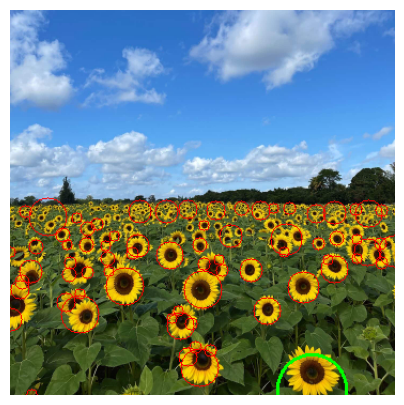

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

im = cv.imread('D:\\University Documents\\UOM\\Semester 05\\IP\\assignment_02\\a2images\\the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "image not found - check the path"

# Flower-head map (yellow petals + brown centre) used as the blob image
b, g, r = [c.astype(np.float32) / 255.0 for c in cv.split(im)]
f = cv.GaussianBlur(((r > 0.95 * g) & (r - b > 0.12)).astype(np.float32), (0, 0), 1.0)

# Scale-space of scale-normalised LoG
sigma_min, sigma_max, k, thresh = 3.0, 30.0, 1.2, 0.3
sigmas = []
s = sigma_min
while s <= sigma_max:
    sigmas.append(s)
    s *= k
sigmas = np.array(sigmas)

stack = []
for sigma in sigmas:
    ks = int(2 * np.ceil(3 * sigma) + 1)
    L = cv.Laplacian(cv.GaussianBlur(f, (ks, ks), sigma), cv.CV_32F, ksize=3)
    stack.append(-(sigma ** 2) * L)          # bright blob -> positive peak
stack = np.stack(stack)

mask = (stack == maximum_filter(stack, size=(3, 3, 3))) & (stack > thresh)
mask[0] = mask[-1] = False
si, ys, xs = np.nonzero(mask)

# Circles (x, y, r = sqrt(2)*sigma); keep strongest, drop overlapping centres
cand = sorted([(x, y, np.sqrt(2) * sigmas[i], sigmas[i], stack[i, y, x])
               for i, y, x in zip(si, ys, xs)], key=lambda c: -c[4])
circles = []
for c in cand:
    if all(np.hypot(c[0] - d[0], c[1] - d[1]) >= 0.8 * max(c[2], d[2]) for d in circles):
        circles.append(c)
circles.sort(key=lambda c: -c[2])

print(f"sigma range used: {sigmas[0]:.2f} to {sigmas[-1]:.2f} ({len(sigmas)} scales, k={k})")
print(f"sigma range of valid extrema: {sigmas[1]:.2f} to {sigmas[-2]:.2f}")
print(f"circles detected: {len(circles)}")
print("largest circles:")
for x, y, rad, sg, _ in circles[:5]:
    print(f"  centre=({x}, {y})  radius={rad:.1f}px  sigma={sg:.2f}")

out = cv.cvtColor(im, cv.COLOR_BGR2RGB)
for x, y, rad, *_ in circles:
    cv.circle(out, (int(x), int(y)), int(round(rad)), (255, 0, 0), 1)
x, y, rad, *_ = circles[0]
cv.circle(out, (int(x), int(y)), int(round(rad)), (0, 255, 0), 2)   # largest in green
plt.figure(figsize=(5, 5)); plt.imshow(out); plt.axis('off'); plt.show()

Applying the LoG directly to grayscale failed because clouds are brighter blobs than the flowers, so I used a flower-head mask (yellow petals plus brown centre) as the blob image. Each head then becomes one filled disc, and the circles sit on the heads. Small sigma value (about 3.6 to 6) finds the many tiny distant flowers, sigma ~= 10 to 13 finds the mid-field heads, and sigma ~= 22 finds the large foreground head. The first and last scales are not true extrema, since they have only one scale neighbour, so they are ignored and the valid range is sigma = 3.6 to 22.3. In total 73 circles were detected. The largest has centre (282, 354), sigma ~= 22.29 and r ~= 31.5 px. It is cut by the image border, so its radius is probably slightly overestimated.

## Question 02

threshold=1.96, min consensus=35, iterations=100
RANSAC sample model: a=0.737 b=0.676 d=1.095, inliers=57
Refit (TLS): a=0.7204 b=0.6936 d=1.4812  |n|=1.000  inliers=58
True line y=-x+2: a=0.7071 b=0.7071 d=1.4142
true line points among inliers: 50/50, circle points among inliers: 8


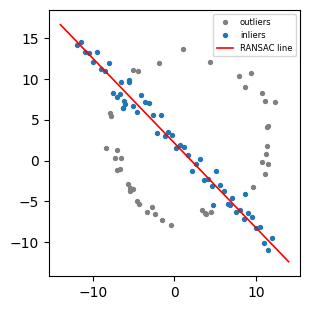

In [ ]:
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3                       
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.                                  
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))          

# RANSAC line fit: a*x + b*y = d with a^2 + b^2 = 1 
def line_from_two(p, q):
    dx, dy = q - p
    nrm = np.hypot(dx, dy)
    a, b = -dy / nrm, dx / nrm            
    return a, b, a * p[0] + b * p[1]

def tls_line(P):                          # total least squares on the consensus set
    mu = P.mean(axis=0)
    _, V = np.linalg.eigh(np.cov((P - mu).T))
    a, b = V[:, 0]                        # smallest-eigenvalue eigenvector = unit normal
    d = a * mu[0] + b * mu[1]
    return (a, b, d) if d >= 0 else (-a, -b, -d)

thresh = 1.96 * s                         # ~95% of true line points within 1.96*sigma
min_inliers = 35                          # 70% of the 50 line points
iters = 100
rng = np.random.default_rng(0)
best_in, best_model = None, None
for _ in range(iters):
    i, j = rng.choice(len(X), 2, replace=False)
    a, b, d = line_from_two(X[i], X[j])
    inl = np.abs(X @ np.array([a, b]) - d) < thresh   # normal distance to the line
    if inl.sum() >= min_inliers and (best_in is None or inl.sum() > best_in.sum()):
        best_in, best_model = inl, (a, b, d)

a, b, d = tls_line(X[best_in])
inl = np.abs(X @ np.array([a, b]) - d) < thresh
print(f"threshold={thresh:.2f}, min consensus={min_inliers}, iterations={iters}")
print(f"RANSAC sample model: a={best_model[0]:.3f} b={best_model[1]:.3f} d={best_model[2]:.3f}, inliers={best_in.sum()}")
print(f"Refit (TLS): a={a:.4f} b={b:.4f} d={d:.4f}  |n|={np.hypot(a,b):.3f}  inliers={inl.sum()}")
print(f"True line y=-x+2: a={1/np.sqrt(2):.4f} b={1/np.sqrt(2):.4f} d={2/np.sqrt(2):.4f}")
print(f"true line points among inliers: {inl[half_n:].sum()}/50, circle points among inliers: {inl[:half_n].sum()}")

xx = np.array([-14, 14])
plt.figure(figsize=(3.2, 3.2))
plt.scatter(*X[~inl].T, s=8, c='gray', label='outliers')
plt.scatter(*X[inl].T, s=8, c='tab:blue', label='inliers')
plt.plot(xx, (d - a * xx) / b, 'r-', lw=1.2, label='RANSAC line')
plt.axis('equal'); plt.legend(fontsize=6); plt.tight_layout(); plt.show()

The noise is large (sigma = 1), so the threshold has to be wide, and that lets in the 8 circle points. This slightly biases the fitted line. The estimate is still close to the truth, with the normal rotated by about 1 degree and d off by about 0.07.
The sample model from just 2 points (d = 1.095) is noticeably worse than the refit (d = 1.481), so refitting on the consensus set is worthwhile.
A bigger consensus requirement makes a wrong line unlikely to win, because a line through the circle can’t gather 35 points.

remnant points: 42, radial threshold=1.225, min consensus=30, iterations=200
RANSAC sample circle: centre=(1.717,3.071) r=9.876 inliers=40
Refit: centre=(1.836,3.049) r=9.901 inliers=40
Ground truth: centre=(2,3) r=10


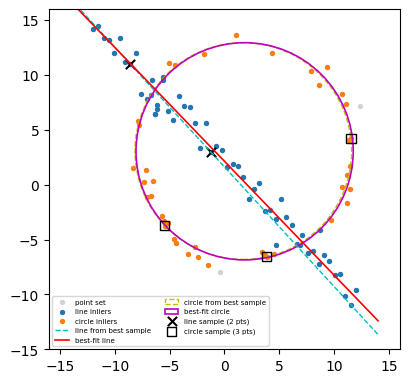

In [10]:
from scipy.optimize import minimize

#(b) RANSAC circle on the remnant 
R = X[~inl]                                

def circle_from_three(p1, p2, p3):         
    A = 2 * np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-9:       
        return None
    c = np.linalg.solve(A, np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1]))
    return c, np.linalg.norm(p1 - c)

def radial_err(P, c, rad):                 
    return np.abs(np.linalg.norm(P - c, axis=1) - rad)

def fit_circle(P, c0, r0):                 # least squares on radial error
    cost = lambda q: np.sum(radial_err(P, q[:2], q[2]) ** 2)
    q = minimize(cost, [c0[0], c0[1], r0], method='Nelder-Mead',
                 options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 2000}).x
    return q[:2], q[2]

sig_c = r / 16                             
thresh_c = 1.96 * sig_c                    
min_c = 30                                
iters_c = 200
best_c, circ_sample = None, None
for _ in range(iters_c):
    idx = rng.choice(len(R), 3, replace=False)
    out = circle_from_three(*R[idx])
    if out is None:
        continue
    c, rad = out
    ic = radial_err(R, c, rad) < thresh_c
    if ic.sum() >= min_c and (best_c is None or ic.sum() > best_c[0].sum()):
        best_c, circ_sample = (ic, c, rad), R[idx]

ic, c0, r0 = best_c
c_fit, r_fit = fit_circle(R[ic], c0, r0)
ic_final = radial_err(R, c_fit, r_fit) < thresh_c
print(f"remnant points: {len(R)}, radial threshold={thresh_c:.3f}, min consensus={min_c}, iterations={iters_c}")
print(f"RANSAC sample circle: centre=({c0[0]:.3f},{c0[1]:.3f}) r={r0:.3f} inliers={ic.sum()}")
print(f"Refit: centre=({c_fit[0]:.3f},{c_fit[1]:.3f}) r={r_fit:.3f} inliers={ic_final.sum()}")
print(f"Ground truth: centre=({x0_gt},{y0_gt}) r={r}")

#(c) everything in one plot 
# recover the best 2-point line sample 
rng2 = np.random.default_rng(0)
best_n, line_sample = -1, None
for _ in range(iters):
    i, j = rng2.choice(len(X), 2, replace=False)
    a_, b_, d_ = line_from_two(X[i], X[j])
    n_ = (np.abs(X @ np.array([a_, b_]) - d_) < thresh).sum()
    if n_ >= min_inliers and n_ > best_n:
        best_n, line_sample = n_, X[[i, j]]

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(*X.T, s=8, c='lightgray', label='point set')
ax.scatter(*X[inl].T, s=8, c='tab:blue', label='line inliers')
ax.scatter(*R[ic_final].T, s=8, c='tab:orange', label='circle inliers')
la, lb, ld = best_model
ax.plot(xx, (ld - la * xx) / lb, 'c--', lw=1, label='line from best sample')
ax.plot(xx, (d - a * xx) / b, 'r-', lw=1.2, label='best-fit line')
ax.add_patch(plt.Circle(c0, r0, color='y', fill=False, ls='--', lw=1, label='circle from best sample'))
ax.add_patch(plt.Circle(c_fit, r_fit, color='m', fill=False, lw=1.2, label='best-fit circle'))
ax.scatter(*line_sample.T, s=45, marker='x', c='k', label='line sample (2 pts)')
ax.scatter(*circ_sample.T, s=45, marker='s', facecolors='none', edgecolors='k', label='circle sample (3 pts)')
ax.set_aspect('equal'); ax.set_xlim(-16, 16); ax.set_ylim(-15, 16)
ax.legend(fontsize=5, loc='lower left', ncol=2); plt.tight_layout(); plt.show()

Subtracting the line consensus first is what makes the circle fit easy. The remnant contains only circle points, so the first RANSAC sample already reaches a consensus of 42. 
40 of the 42 points lie inside the threshold after the refit. The other two are noisy points beyond 1.96 sigma, which is expected for Gaussian noise.
The 8 circle points removed with the line (they lay near the line) leave gaps on the circle, but the fit still comes out right. Even with fewer points, the circle is fully determined by the rest.

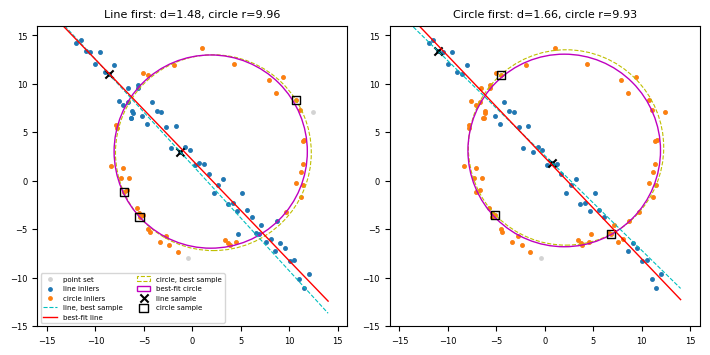

In [12]:
# Compare both orders: left = line first then circle, right = circle first then line
def ransac_line_fn(P, rng, thr=thresh, min_in=30, n_it=100):
    best = None
    for _ in range(n_it):
        i, j = rng.choice(len(P), 2, replace=False)
        a_, b_, d_ = line_from_two(P[i], P[j])
        m_ = np.abs(P @ np.array([a_, b_]) - d_) < thr
        if m_.sum() >= min_in and (best is None or m_.sum() > best[0].sum()):
            best = (m_, (a_, b_, d_), P[[i, j]])
    fit = tls_line(P[best[0]])
    return dict(inl=np.abs(P @ np.array(fit[:2]) - fit[2]) < thr, model=best[1], sample=best[2], fit=fit)

def ransac_circle_fn(P, rng, thr=thresh_c, min_in=30, n_it=200):
    best = None
    for _ in range(n_it):
        idx = rng.choice(len(P), 3, replace=False)
        o = circle_from_three(*P[idx])
        if o is None:
            continue
        m_ = radial_err(P, *o) < thr
        if m_.sum() >= min_in and (best is None or m_.sum() > best[0].sum()):
            best = (m_, o, P[idx])
    c_, r_ = fit_circle(P[best[0]], *best[1])
    return dict(inl=radial_err(P, c_, r_) < thr, model=best[1], sample=best[2], fit=(c_, r_))

# line first
rng = np.random.default_rng(0)
Lf = ransac_line_fn(X, rng)
rem = np.where(~Lf['inl'])[0]
Cf = ransac_circle_fn(X[rem], rng)
# circle first
rng = np.random.default_rng(0)
Cs = ransac_circle_fn(X, rng)
rem2 = np.where(~Cs['inl'])[0]
Ls = ransac_line_fn(X[rem2], rng)

def draw(ax, L, C, line_pts, circ_pts, title):
    ax.scatter(*X.T, s=6, c='lightgray', label='point set')
    ax.scatter(*line_pts[L['inl']].T, s=6, c='tab:blue', label='line inliers')
    ax.scatter(*circ_pts[C['inl']].T, s=6, c='tab:orange', label='circle inliers')
    a_, b_, d_ = L['model']; ax.plot(xx, (d_ - a_ * xx) / b_, 'c--', lw=0.8, label='line, best sample')
    a_, b_, d_ = L['fit'];   ax.plot(xx, (d_ - a_ * xx) / b_, 'r-', lw=1, label='best-fit line')
    ax.add_patch(plt.Circle(*C['model'], color='y', fill=False, ls='--', lw=0.8, label='circle, best sample'))
    ax.add_patch(plt.Circle(*C['fit'], color='m', fill=False, lw=1, label='best-fit circle'))
    ax.scatter(*L['sample'].T, s=35, marker='x', c='k', label='line sample')
    ax.scatter(*C['sample'].T, s=35, marker='s', facecolors='none', edgecolors='k', label='circle sample')
    ax.set_title(title, fontsize=8); ax.set_aspect('equal'); ax.set_xlim(-16, 16); ax.set_ylim(-15, 16)
    ax.tick_params(labelsize=6)

fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.8))
draw(axs[0], Lf, Cf, X, X[rem], f"Line first: d={Lf['fit'][2]:.2f}, circle r={Cf['fit'][1]:.2f}")
draw(axs[1], Ls, Cs, X[rem2], X, f"Circle first: d={Ls['fit'][2]:.2f}, circle r={Cs['fit'][1]:.2f}")
axs[0].legend(fontsize=5, loc='lower left', ncol=2)
plt.tight_layout(); plt.show()

If the circle is fitted first, it still comes out well (centre (1.996, 3.133), r = 9.93), but it also absorbs 9 line points where the line crosses the ring. The line is then fitted on fewer points and is biased (d = 1.66 vs the true 1.41; line first gave 1.48). A circle of very large radius can also mimic the line, so RANSAC may pick it instead of the real circle. In 200 simulated datasets, the circle was correct in 178 runs when fitted first, against 199 for line first. Line first is therefore the better order.

## Question 03

[D:\University Documents\UOM\Semester 05\IP\assignment_02\output1.jpg] Computed Homography H =
[[ 4.7485000e-01 -1.8600000e-03  2.3343159e+02]
 [ 0.0000000e+00  4.7438000e-01  1.3644976e+02]
 [ 0.0000000e+00 -0.0000000e+00  1.0000000e+00]]



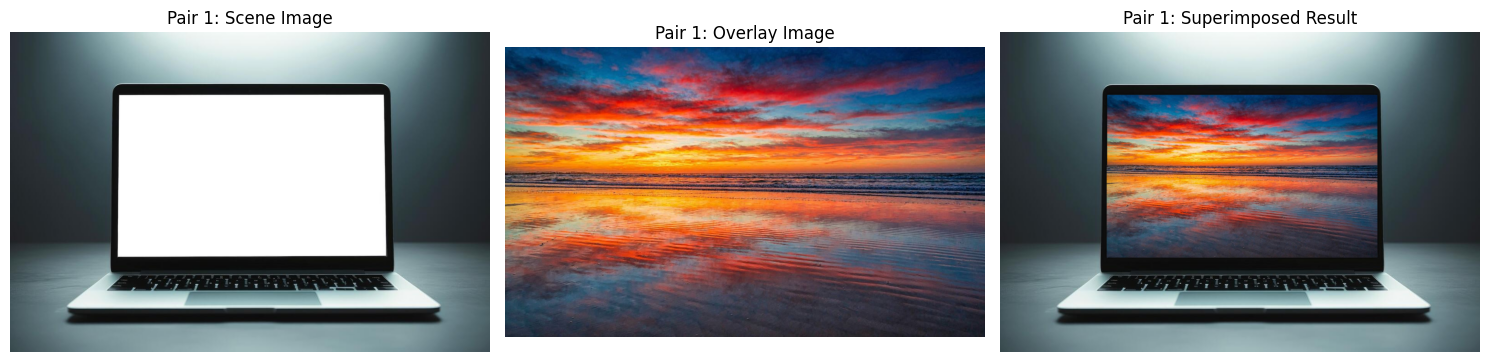

[D:\University Documents\UOM\Semester 05\IP\assignment_02\output2.jpg] Computed Homography H =
[[ 3.25360e+00 -8.47300e-02  2.48000e+02]
 [ 7.11250e-01  2.63078e+00  1.88000e+02]
 [ 5.40000e-04 -2.00000e-04  1.00000e+00]]



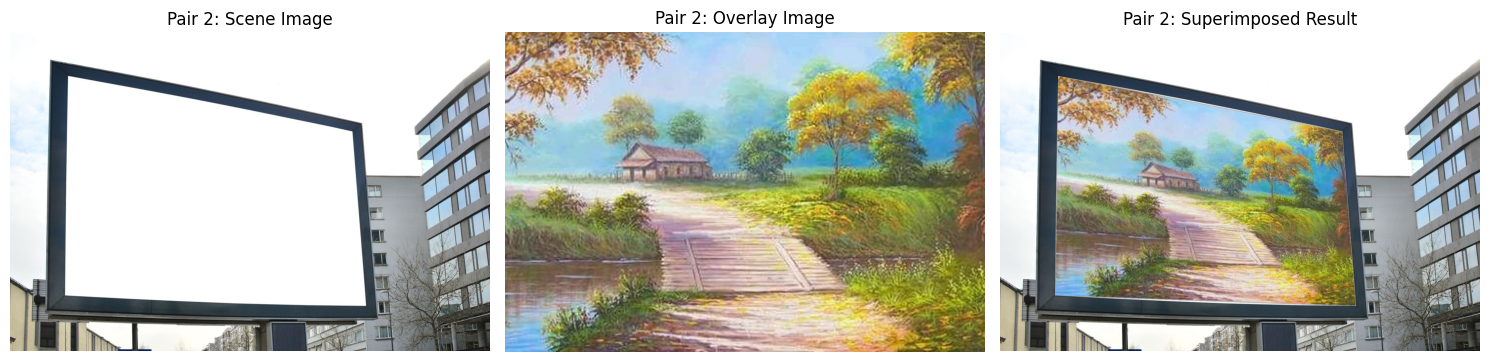

In [ ]:
import sys
# Step 1: Point Selection & Auto-Detection
def click_points(scene_bgr, n=4):
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(scene_bgr, cv2.COLOR_BGR2RGB))
    plt.title(f"Click {n} corners in order: top-left, top-right, "
              f"bottom-right, bottom-left")
    pts = plt.ginput(n, timeout=0)
    plt.close()
    if len(pts) != n:
        raise RuntimeError("Did not receive all clicks.")
    return [(float(x), float(y)) for x, y in pts]


def get_billboard_corners(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        raise ValueError("No bright white surface found for automatic detection.")

    largest_contour = max(contours, key=cv2.contourArea)
    epsilon = 0.02 * cv2.arcLength(largest_contour, True)
    approx = cv2.approxPolyDP(largest_contour, epsilon, True)
    
    if len(approx) == 4:
        pts = approx.reshape(4, 2)
    else:
        rect = cv2.minAreaRect(largest_contour)
        pts = cv2.boxPoints(rect)
    
    # Sort points: Top-Left, Top-Right, Bottom-Right, Bottom-Left
    pts = sorted(pts, key=lambda p: p[1])
    top_two = sorted(pts[:2], key=lambda p: p[0])
    bottom_two = sorted(pts[2:], key=lambda p: p[0])
    
    return [
        (float(top_two[0][0]), float(top_two[0][1])),       
        (float(top_two[1][0]), float(top_two[1][1])),       
        (float(bottom_two[1][0]), float(bottom_two[1][1])),
        (float(bottom_two[0][0]), float(bottom_two[0][1])) 
    ]


# Step 2: Homography via Normalised DLT + SVD
def _normalise(pts):
    pts = np.asarray(pts, dtype=np.float64)
    c = pts.mean(axis=0)
    d = np.sqrt(((pts - c) ** 2).sum(axis=1)).mean()
    s = np.sqrt(2) / d
    T = np.array([[s, 0, -s * c[0]],
                  [0, s, -s * c[1]],
                  [0, 0, 1]])
    ph = np.hstack([pts, np.ones((len(pts), 1))])
    return (T @ ph.T).T[:, :2], T


def compute_homography(src, dst):
    src_n, T1 = _normalise(src)
    dst_n, T2 = _normalise(dst)
    A = []
    for (x, y), (u, v) in zip(src_n, dst_n):
        A.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        A.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    A = np.array(A)
    _, _, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3, 3)
    H = np.linalg.inv(T2) @ Hn @ T1
    return H / H[2, 2]


# Step 3: Warp by Inverse Mapping + Bilinear Interpolation
def bilinear_sample(img, x, y):
    h, w = img.shape[:2]
    x0 = np.clip(np.floor(x).astype(int), 0, w - 2)
    y0 = np.clip(np.floor(y).astype(int), 0, h - 2)
    dx = (x - x0)[:, None]
    dy = (y - y0)[:, None]
    Ia = img[y0, x0].astype(np.float64)
    Ib = img[y0, x0 + 1].astype(np.float64)
    Ic = img[y0 + 1, x0].astype(np.float64)
    Id = img[y0 + 1, x0 + 1].astype(np.float64)
    return (Ia * (1 - dx) * (1 - dy) + Ib * dx * (1 - dy) +
            Ic * (1 - dx) * dy + Id * dx * dy)


def warp_with_homography(overlay, H, out_shape):
    hs, ws = out_shape[:2]
    ho, wo = overlay.shape[:2]
    Hinv = np.linalg.inv(H)

    ys, xs = np.mgrid[0:hs, 0:ws]
    pix = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)])
    src = Hinv @ pix
    sx, sy = src[0] / src[2], src[1] / src[2]

    valid = (sx >= 0) & (sx <= wo - 1) & (sy >= 0) & (sy <= ho - 1) & (src[2] != 0)
    warped = np.zeros((hs * ws, 3), dtype=np.float64)
    warped[valid] = bilinear_sample(overlay, sx[valid], sy[valid])
    return warped.reshape(hs, ws, 3), valid.reshape(hs, ws).astype(np.float32)


# Step 4: Blending
def blend(scene, warped, mask, alpha=1.0, feather=3):
    m = cv2.GaussianBlur(mask, (0, 0), feather) if feather > 0 else mask
    m = np.maximum(m, cv2.erode(mask, np.ones((3, 3), np.uint8)))
    m = (alpha * m)[..., None]
    out = scene.astype(np.float64) * (1 - m) + warped * m
    return np.clip(out, 0, 255).astype(np.uint8)


# Helpers & Execution Pipeline
def crop_to_aspect(img, target_aspect):
    """Centre-crop img to match the target aspect ratio."""
    h, w = img.shape[:2]
    if w / h > target_aspect:
        new_w = int(round(h * target_aspect))
        x0 = (w - new_w) // 2
        return img[:, x0:x0 + new_w]
    new_h = int(round(w / target_aspect))
    y0 = (h - new_h) // 2
    return img[y0:y0 + new_h, :]


def overlay_pair(scene_path, overlay_path, out_path, points=None,
                 auto_detect=False, crop=True, alpha=1.0, grow=0.0):
    scene = cv2.imread(scene_path)
    overlay = cv2.imread(overlay_path)
    if scene is None or overlay is None:
        raise FileNotFoundError(f"Could not read images at {scene_path} or {overlay_path}.")

    if auto_detect:
        try:
            pts = get_billboard_corners(scene)
        except Exception as e:
            print(f"Auto-detection failed ({e}), using provided points/clicks.")
            pts = points if points is not None else click_points(scene)
    elif points is not None:
        pts = points
    else:
        pts = click_points(scene)

    dst = np.array(pts, dtype=np.float64)
    if grow:
        c = dst.mean(axis=0)
        v = dst - c
        dst = dst + grow * v / np.linalg.norm(v, axis=1, keepdims=True)

    if crop:
        w_q = (np.linalg.norm(dst[1] - dst[0]) + np.linalg.norm(dst[2] - dst[3])) / 2
        h_q = (np.linalg.norm(dst[3] - dst[0]) + np.linalg.norm(dst[2] - dst[1])) / 2
        overlay = crop_to_aspect(overlay, w_q / h_q)

    ho, wo = overlay.shape[:2]
    src = np.array([[0, 0], [wo - 1, 0], [wo - 1, ho - 1], [0, ho - 1]], float)

    H = compute_homography(src, dst)
    warped, mask = warp_with_homography(overlay, H, scene.shape)
    result = blend(scene, warped, mask, alpha=alpha)

    cv2.imwrite(out_path, result)
    print(f"[{out_path}] Computed Homography H =\n{np.round(H, 5)}\n")
    return scene, overlay, result


def show_results(scene, overlay, result, title_prefix="Pair"):
    """Displays Scene, Overlay, and Result inline under the execution cell."""
    imgs = [scene, overlay, result]
    titles = ["Scene Image", "Overlay Image", "Superimposed Result"]
    plt.figure(figsize=(15, 5))
    for i, (im, t) in enumerate(zip(imgs, titles)):
        plt.subplot(1, 3, i + 1)
        plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        plt.title(f"{title_prefix}: {t}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


PAIRS = [
    # Pair 1: Laptop Screen & Overlay Image
    {
        "scene": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\laptop_screen.jpg",
        "overlay": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\window.jpg",
        "output": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\output1.jpg",
        "points": [(236, 138), (823, 138), (823, 492), (235, 492)],
        "auto_detect": False,
        "grow": 3
    },
    # Pair 2: Billboard Screen & Landscape Painting
    {
        "scene": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\screen.jpg",
        "overlay": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\image.jpg",
        "output": r"D:\University Documents\UOM\Semester 05\IP\assignment_02\output2.jpg",
        "points": None,  # Will auto-detect screen boundaries
        "auto_detect": True,
        "grow": 0
    }
]

if __name__ == "__main__":
    for idx, pair in enumerate(PAIRS, 1):
        scene, overlay, result = overlay_pair(
            scene_path=pair["scene"],
            overlay_path=pair["overlay"],
            out_path=pair["output"],
            points=pair["points"],
            auto_detect=pair["auto_detect"],
            grow=pair["grow"]
        )
        show_results(scene, overlay, result, title_prefix=f"Pair {idx}")

To superimpose images onto planar surfaces, the system employs a theoretical pipeline based on normalized Direct Linear Transform (DLT) and bilinear inverse mapping. Given four corresponding point pairs selected manually or via automated contour detection, Hartley normalization centers and scales the coordinate sets to prevent numerical instability during matrix decomposition. The homography matrix H is then computed via Singular Value Decomposition on the resulting algebraic linear system A. To avoid structural gaps or sampling artifacts on the destination canvas, the system computes H^{-1} to map each target coordinate back into the source space, interpolating pixel intensities using bilinear sampling. Finally, the warped image is blended onto the scene using Gaussian boundary feathering to soften transition edges. Across both case studies—a laptop display and an outdoor billboard—this approach demonstrated precise geometric alignment with the underlying perspective plane, though success relies on accurate corner selection and assumes unoccluded planar surfaces.